In [2]:
import pandas as pd
d=pd.read_csv('/home/mylinux/Desktop/MTech_Project/MTP/Classroom-engagement-system/results/video_test/student_data1.csv')
s=d.groupby('student_id').agg(first_frame=('frame','min'),last_frame=('frame','max'),observations=('frame','count')); s['span_seconds']=(s.last_frame-s.first_frame)/25
print(s.to_string())

            first_frame  last_frame  observations  span_seconds
student_id                                                     
1                     1          24            24          0.92
2                     1          36            36          1.40
3                     1          27            27          1.04
4                     1          26            26          1.00
5                     1          24            24          0.92
6                     1          22            22          0.84
7                     1          23            23          0.88
8                     1          21            21          0.80
9                     1          29            24          1.12
10                    1          26            20          1.00
11                   17          24             8          0.28
16                   37          43             7          0.24
18                   38         291           251         10.12
19                   39          39     

In [4]:
import pandas as pd; d=pd.read_csv('/home/mylinux/Desktop/MTech_Project/MTP/Classroom-engagement-system/results/video_test/student_data1.csv'); d['time_bin']=(d['frame']-1)//25; print(d.groupby('time_bin').agg(unique_tracks=('student_id','nunique'),observations=('student_id','size')).to_string())

          unique_tracks  observations
time_bin                             
0                    11           237
1                    15            62
2                    10           192
3                     9           224
4                     9           182
5                     8           190
6                     8           200
7                     8           186
8                     8           195
9                     8           192
10                    8           193
11                   13            56
12                    8           169
13                    8           191
14                    8           194
15                    7           169
16                    8           183
17                    7           175
18                    7           170
19                    8           192
20                    8           181
21                   10            54
22                    3            73
23                    3            75
24          

In [5]:
import pandas as pd

df = pd.read_csv("../results/video_test/student_data1.csv")

regions = {
    "Region 1": (50, 249),
    "Region 2": (300, 499),
    "Region 3": (550, 749)
}

for name, (start, end) in regions.items():
    data = df[df["frame"].between(start, end)]

    print(f"\n{name}")
    print("Unique tracks:", data["student_id"].nunique())
    print("Total observations:", len(data))
    print("\nObservations per track:")
    print(data.groupby("student_id").size().sort_values(ascending=False))


Region 1
Unique tracks: 10
Total observations: 1561

Observations per track:
student_id
18    200
25    200
30    200
27    200
28    200
29    200
31    199
32    130
33     30
24      2
dtype: int64

Region 2
Unique tracks: 10
Total observations: 1441

Observations per track:
student_id
35    200
38    200
39    200
41    199
42    199
43    197
44    172
25     49
46     17
45      8
dtype: int64

Region 3
Unique tracks: 3
Total observations: 596

Observations per track:
student_id
49    200
58    199
59    197
dtype: int64


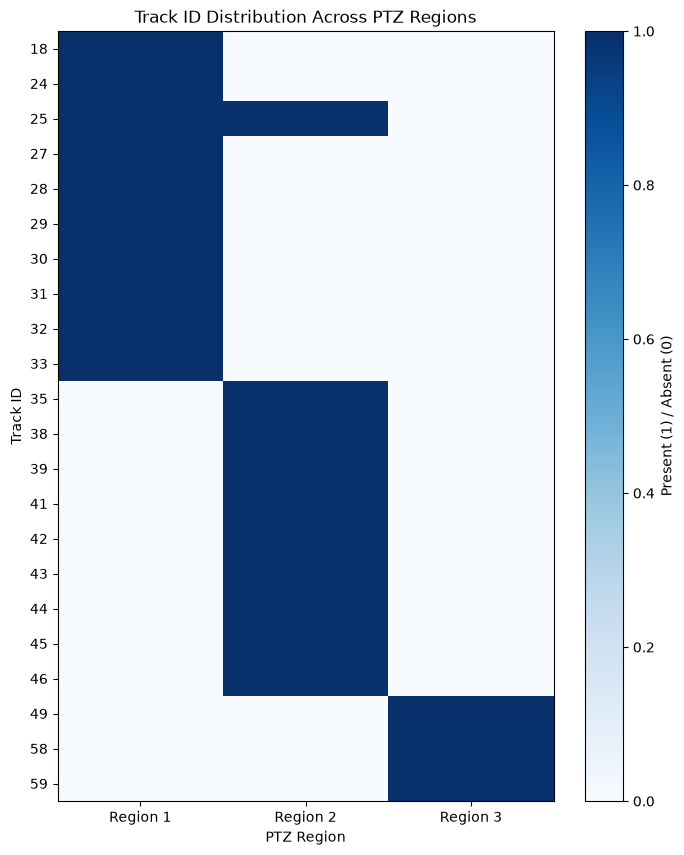

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

region_data = []

for region, (start, end) in regions.items():
    temp = df[df["frame"].between(start, end)]

    for sid in temp["student_id"].unique():
        region_data.append({
            "Region": region,
            "Student_ID": sid
        })

plot_df = pd.DataFrame(region_data)

pivot = plot_df.pivot_table(
    index="Student_ID",
    columns="Region",
    aggfunc="size",
    fill_value=0
)

plt.figure(figsize=(8, 10))
plt.imshow(pivot > 0, aspect="auto", cmap="Blues")

plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("PTZ Region")
plt.ylabel("Track ID")
plt.title("Track ID Distribution Across PTZ Regions")
plt.colorbar(label="Present (1) / Absent (0)")
plt.show()

In [7]:
import inspect; from ultralytics.trackers.byte_tracker import BYTETracker; print(inspect.getsource(BYTETracker.reset))

    def reset(self):
        """Reset the tracker by clearing all tracked, lost, and removed tracks and reinitializing the Kalman filter."""
        self.tracked_stracks = []
        self.lost_stracks = []
        self.removed_stracks = []
        self.frame_id = 0
        self.kalman_filter = self.get_kalmanfilter()
        self.reset_id()



In [2]:
import pandas as pd

df = pd.read_csv("../results/video_test/student_data1.csv")

print("Total observations:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nObservations per region:")
print(df.groupby("region_id").size())

print("\nUnique students per region:")
print(df.groupby("region_id")["student_id"].nunique())

print("\nStudent IDs per region:")
print(df.groupby("region_id")["student_id"].unique())

Total observations: 3601

Columns:
['frame', 'time', 'region_idstudent_id', 'yaw', 'pitch', 'roll', 'left_ear', 'right_ear', 'avg_ear', 'eye_state', 'gaze', 'torso_angle', 'left_knee_angle', 'right_knee_angle']

Observations per region:


KeyError: 'region_id'